# Comparing nonlinear filters on the same observations

**Notebook author: Ziad Mosalam**  
Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems*, by Khalid M. Mosalam.

An EKF, a UKF and a particle filter can produce almost indistinguishable trajectories. That is a useful result when it follows from a fair comparison. Here each method receives the same controls, observations, prior and noise variances. We compare accuracy, interval coverage and normalized diagnostics across 64 independent synthetic runs. The experiment retains the model and seeds used for the book's matched-filter example.

Run the notebook from top to bottom. It displays and exports two figures to `../figures/`. NumPy, SciPy and Matplotlib perform all calculations here; no numerical code is hidden in another module. The shared `book.mplstyle` file controls appearance only.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.special import logsumexp
from scipy.stats import t as student_t

plt.style.use('book.mplstyle')
figures = Path('../figures')
figures.mkdir(exist_ok=True)

methods = ('EKF', 'UKF', 'PF')
colors = ('#247C86', '#B17A00', '#003262')
line_styles = ('-', '--', '-.')
markers = ('o', 's', 'D')
ink = '#30363B'

## Model and experiment

The scalar state is dimensionless. Its transition and observation models are

\[
x_{k+1}=0.9x_k+0.1\sin x_k+u_k+w_k,\qquad
u_k=0.15\cos(0.1k),
\]
\[
z_{k+1}=x_{k+1}+0.15x_{k+1}^2+v_{k+1}.
\]

The initial state has distribution $\mathcal N(1,0.5)$, while $w_k\sim\mathcal N(0,0.025)$ and $v_k\sim\mathcal N(0,0.09)$ are independent. These numbers are variances. No measured field data enter the example.

Each run draws one complete state and observation sequence. A separate random stream drives the particles, so changing the particle calculation cannot change the data seen by the other filters. We keep the initial prior and known model parameters identical across methods.

In [2]:
config = dict(
    steps=80, runs=64, first_seed=20261111, particles=2000,
    initial_mean=1.0, initial_variance=0.5,
    process_variance=0.025, measurement_variance=0.09,
    transition_coefficient=0.9, transition_sine=0.1,
    control_amplitude=0.15, measurement_quadratic=0.15,
    ukf_alpha=0.7, ukf_beta=2.0, ukf_kappa=0.0,
    ess_fraction=0.5,
)


def transition(x, u, cfg):
    return cfg['transition_coefficient']*x + cfg['transition_sine']*np.sin(x) + u


def transition_jacobian(x, cfg):
    return cfg['transition_coefficient'] + cfg['transition_sine']*np.cos(x)


def measurement(x, cfg):
    return x + cfg['measurement_quadratic']*x*x


def measurement_jacobian(x, cfg):
    return 1 + 2*cfg['measurement_quadratic']*x

## Gaussian approximations

The EKF propagates a mean and variance using the local derivatives of $f$ and $h$. Its covariance update uses the scalar Joseph form to avoid subtracting nearly equal quantities.

The UKF uses three sigma points. With $c=\alpha^2(1+\kappa)$, their displacements from the mean are $0$ and $\pm\sqrt{cP}$. The mean weights are $1-1/c,1/(2c),1/(2c)$; the central covariance weight also includes $1-\alpha^2+\beta$. After adding process noise to the predicted variance, we generate a fresh set of sigma points before applying the observation model. Otherwise that noise would be absent from the observation statistics.

Both filters report a Gaussian central interval $\hat x\pm1.95996\sqrt P$. Its actual coverage in this nonlinear problem is checked rather than assumed.

In [3]:
def sigma_points(mu, variance, cfg):
    alpha, beta, kappa = cfg['ukf_alpha'], cfg['ukf_beta'], cfg['ukf_kappa']
    c = alpha*alpha*(1 + kappa)
    points = mu + np.array([0., 1., -1.])*np.sqrt(c*variance)
    mean_weights = np.array([(c - 1)/c, 1/(2*c), 1/(2*c)])
    covariance_weights = mean_weights.copy()
    covariance_weights[0] += 1 - alpha*alpha + beta
    return points, mean_weights, covariance_weights


def gaussian_step(mu, P, u, z, cfg, method):
    Q, R = cfg['process_variance'], cfg['measurement_variance']
    if method == 'EKF':
        predicted_mean = transition(mu, u, cfg)
        F = transition_jacobian(mu, cfg)
        predicted_variance = F*P*F + Q
        predicted_observation = measurement(predicted_mean, cfg)
        H = measurement_jacobian(predicted_mean, cfg)
        S = H*predicted_variance*H + R
        K = predicted_variance*H/S
        posterior_mean = predicted_mean + K*(z - predicted_observation)
        posterior_variance = (1 - K*H)**2*predicted_variance + K*K*R
    elif method == 'UKF':
        points, wm, wc = sigma_points(mu, P, cfg)
        propagated = transition(points, u, cfg)
        predicted_mean = float(wm @ propagated)
        predicted_variance = float(wc @ ((propagated - predicted_mean)**2) + Q)
        points, wm, wc = sigma_points(predicted_mean, predicted_variance, cfg)
        projected = measurement(points, cfg)
        predicted_observation = float(wm @ projected)
        S = float(wc @ ((projected - predicted_observation)**2) + R)
        cross_covariance = float(wc @ ((points - predicted_mean)*(projected - predicted_observation)))
        K = cross_covariance/S
        posterior_mean = predicted_mean + K*(z - predicted_observation)
        posterior_variance = predicted_variance - K*K*S
    else:
        raise ValueError('method must be EKF or UKF')
    return posterior_mean, posterior_variance, z - predicted_observation, S

## Particle weights and intervals

The bootstrap particle filter samples the transition model, multiplies the existing weights by the new likelihood, and normalizes in log space. The mean, variance and weighted 2.5th/97.5th percentiles are recorded **before** resampling. Resampling only occurs when the effective sample size $1/\sum_iw_i^2$ falls below half the particle count.

For the innovation diagnostic, the particle prediction of the observation mean and variance uses the weights *before* the observation is assimilated. Adding $R$ includes observation noise in that predictive variance.

In [4]:
def weighted_quantile(values, weights, probabilities=(.025, .975)):
    # Inverse of the weighted empirical CDF; zero-weight particles do not contribute.
    positive = weights > 0
    values, weights = values[positive], weights[positive]
    order = np.argsort(values)
    cumulative = np.minimum(np.cumsum(weights[order]), 1.)
    cumulative[-1] = 1.
    return values[order][np.searchsorted(cumulative, probabilities)]


def systematic_indices(weights, rng):
    n = len(weights)
    cumulative = np.minimum(np.cumsum(weights), 1.)
    cumulative[-1] = 1.
    positions = (rng.random() + np.arange(n))/n
    return np.searchsorted(cumulative, positions, side='right')

## One run

The first observation is $z_1$, after one transition from $x_0$. Array entry `k` therefore stores the posterior for state $x_{k+1}$. This convention also fixes the horizontal coordinates in the trajectory plots.

In [5]:
def one_run(seed, cfg):
    T, N = cfg['steps'], cfg['particles']
    data_rng = np.random.default_rng(np.random.SeedSequence([seed, 0]))
    particle_rng = np.random.default_rng(np.random.SeedSequence([seed, 1]))
    m0, P0 = cfg['initial_mean'], cfg['initial_variance']
    Q, R = cfg['process_variance'], cfg['measurement_variance']
    controls = cfg['control_amplitude']*np.cos(.1*np.arange(T))

    truth = np.empty(T + 1)
    observations = np.empty(T)
    truth[0] = data_rng.normal(m0, np.sqrt(P0))
    for k in range(T):
        truth[k + 1] = transition(truth[k], controls[k], cfg) + data_rng.normal(0, np.sqrt(Q))
        observations[k] = measurement(truth[k + 1], cfg) + data_rng.normal(0, np.sqrt(R))

    means = np.empty((3, T))
    variances = np.empty_like(means)
    innovations = np.empty_like(means)
    innovation_variances = np.empty_like(means)
    lower, upper = np.empty_like(means), np.empty_like(means)
    for j, method in enumerate(methods[:2]):
        mu, P = m0, P0
        for k, z in enumerate(observations):
            mu, P, innovation, S = gaussian_step(mu, P, controls[k], z, cfg, method)
            means[j, k], variances[j, k] = mu, P
            innovations[j, k], innovation_variances[j, k] = innovation, S
            lower[j, k] = mu - 1.959963984540054*np.sqrt(P)
            upper[j, k] = mu + 1.959963984540054*np.sqrt(P)

    particles = particle_rng.normal(m0, np.sqrt(P0), N)
    log_weights = np.full(N, -np.log(N))
    ess = np.empty(T)
    for k, z in enumerate(observations):
        particles = transition(particles, controls[k], cfg) + particle_rng.normal(0, np.sqrt(Q), N)
        weights = np.exp(log_weights)
        projected = measurement(particles, cfg)
        predicted_observation = weights @ projected
        S = weights @ ((projected - predicted_observation)**2) + R

        log_weights += -.5*((z - projected)**2/R + np.log(2*np.pi*R))
        log_weights -= logsumexp(log_weights)
        weights = np.exp(log_weights)
        mu = weights @ particles
        P = weights @ ((particles - mu)**2)
        means[2, k], variances[2, k] = mu, P
        innovations[2, k], innovation_variances[2, k] = z - predicted_observation, S
        lower[2, k], upper[2, k] = weighted_quantile(particles, weights)
        ess[k] = 1/(weights @ weights)
        if ess[k] < cfg['ess_fraction']*N:
            particles = particles[systematic_indices(weights, particle_rng)]
            log_weights.fill(-np.log(N))

    error = means - truth[None, 1:]
    return dict(
        truth=truth, observations=observations, controls=controls,
        means=means, variances=variances,
        innovations=innovations, innovation_variances=innovation_variances,
        lower=lower, upper=upper, error=error,
        nees=error**2/variances, nis=innovations**2/innovation_variances,
        coverage=(truth[None, 1:] >= lower) & (truth[None, 1:] <= upper), ess=ess,
    )

## Checks before the comparison

An affine model provides a useful limit: the EKF and UKF should then give the same Gaussian update. We also check that the sigma points recover their input mean and variance, and that systematic resampling preserves uniform weights exactly in its index counts. These checks test the calculations rather than the chosen plot style.

In [6]:
points, wm, wc = sigma_points(.4, .7, config)
np.testing.assert_allclose(wm @ points, .4, atol=1e-14)
np.testing.assert_allclose(wc @ ((points - .4)**2), .7, atol=1e-14)
linear_config = dict(config, transition_sine=0., measurement_quadratic=0.)
ekf = gaussian_step(.4, .7, .2, .9, linear_config, 'EKF')
ukf = gaussian_step(.4, .7, .2, .9, linear_config, 'UKF')
np.testing.assert_allclose(ekf, ukf, rtol=1e-12, atol=1e-14)
np.testing.assert_array_equal(
    systematic_indices(np.full(10, .1), np.random.default_rng(1)), np.arange(10)
)

trials = [one_run(config['first_seed'] + i, config) for i in range(config['runs'])]
arrays = {name: np.stack([trial[name] for trial in trials]) for name in trials[0]}
assert all(np.all(np.isfinite(values)) for values in arrays.values())
assert np.all(arrays['variances'] > 0)
assert np.all(arrays['innovation_variances'] > 0)
assert np.all(arrays['lower'] <= arrays['upper'])
assert np.all((arrays['ess'] >= 1 - 1e-10) & (arrays['ess'] <= config['particles'] + 1e-8))
print(f"Checks passed. Simulated {config['runs']} independent runs, each with {config['steps']} observations.")

Checks passed. Simulated 64 independent runs, each with 80 observations.


## A trajectory, with each approximation shown separately

Run 1 is shown without selecting it for an especially good or bad result. The panels share the same axes and true state. Shading is the method's central 95% interval: Gaussian for EKF/UKF, weighted empirical quantiles for PF. A close visual match here is not evidence that the three posterior distributions are identical.

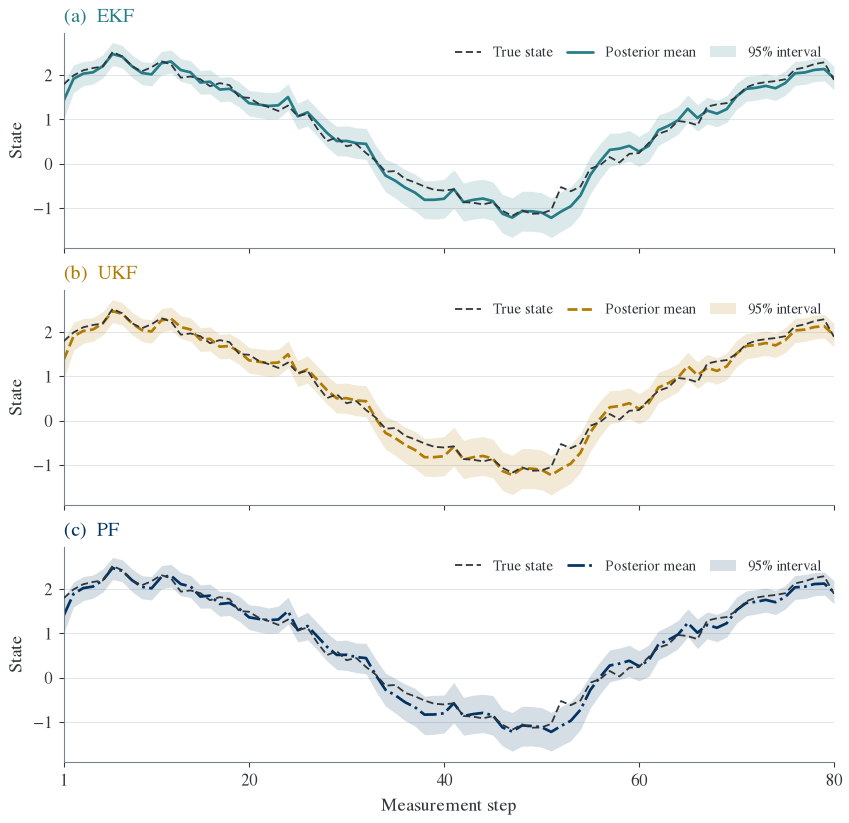

In [7]:
steps = np.arange(1, config['steps'] + 1)
fig, axes = plt.subplots(3, 1, figsize=(6.5, 6.3), sharex=True, sharey=True, layout='constrained')
for j, (ax, method) in enumerate(zip(axes, methods)):
    ax.fill_between(steps, arrays['lower'][0, j], arrays['upper'][0, j],
                    color=colors[j], alpha=.16, linewidth=0)
    ax.plot(steps, arrays['truth'][0, 1:], color=ink, linestyle=(0, (4, 2)), linewidth=1., zorder=3)
    ax.plot(steps, arrays['means'][0, j], color=colors[j], linestyle=line_styles[j], linewidth=1.5)
    ax.set_title(f"({chr(97 + j)})  {method}", loc='left', color=colors[j])
    ax.set_ylabel('State')
    ax.grid(axis='y')
    ax.set_xlim(1, config['steps'])
    handles = [Line2D([], [], color=ink, linestyle=(0, (4, 2)), linewidth=1.),
               Line2D([], [], color=colors[j], linestyle=line_styles[j], linewidth=1.5),
               Patch(facecolor=colors[j], alpha=.16)]
    ax.legend(handles, ['True state', 'Posterior mean', '95% interval'],
              loc='upper right', ncol=3, fontsize=8, handlelength=1.8, columnspacing=1.)
axes[-1].set_xlabel('Measurement step')
axes[-1].set_xticks([1, 20, 40, 60, 80])
fig.savefig(figures / 'comparison-trajectory.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(figures / 'comparison-trajectory.png')
plt.show()

## Accuracy and calibration over independent runs

For each run $r$, define
\[
\mathrm{RMSE}_r=\sqrt{\frac1T\sum_{k=1}^{T}(\hat x_{r,k}-x_{r,k})^2},\qquad
\mathrm{NEES}_{r,k}=\frac{(\hat x_{r,k}-x_{r,k})^2}{P_{r,k}},\qquad
\mathrm{NIS}_{r,k}=\frac{(z_{r,k}-\hat z_{r,k|k-1})^2}{S_{r,k}}.
\]

A normalized diagnostic near one is the scalar Gaussian reference. In this nonlinear experiment it is a diagnostic target, not proof of calibration. Coverage checks how often the reported intervals actually contain the state.

The methods share data **within** each run. Comparing paired RMSE differences removes variation caused by some data sequences simply being harder than others. In the difference plot, positive values mean that the first method in the label has larger RMSE. The axis uses $10^{-3}$ state units so the small differences remain readable without concealing their scale.

Time steps within a run are correlated. The uncertainty bars below therefore use the **64 independent run summaries**, not 5,120 supposedly independent time points. Bars are approximate 95% Student-$t$ intervals for a mean across runs. They quantify Monte Carlo uncertainty for this scenario, not performance over other models or environments.

In [8]:
run_rmse = np.sqrt(np.mean(arrays['error']**2, axis=2))
run_coverage = arrays['coverage'].mean(axis=2)
run_nees = arrays['nees'].mean(axis=2)
run_nis = arrays['nis'].mean(axis=2)
t_multiplier = student_t.ppf(.975, config['runs'] - 1)


def mean_interval(values):
    mean = values.mean(axis=0)
    half_width = t_multiplier*values.std(axis=0, ddof=1)/np.sqrt(len(values))
    return mean, half_width


print('Method   Mean run RMSE   Coverage   Mean NEES   Mean NIS')
for j, method in enumerate(methods):
    print(f'{method:<6}   {run_rmse[:, j].mean():.6f}       '
          f'{run_coverage[:, j].mean():.4f}     {run_nees[:, j].mean():.4f}      {run_nis[:, j].mean():.4f}')

Method   Mean run RMSE   Coverage   Mean NEES   Mean NIS
EKF      0.186617       0.9451     1.0138      0.9900
UKF      0.186707       0.9477     1.0081      0.9891
PF       0.186732       0.9453     1.0107      0.9923


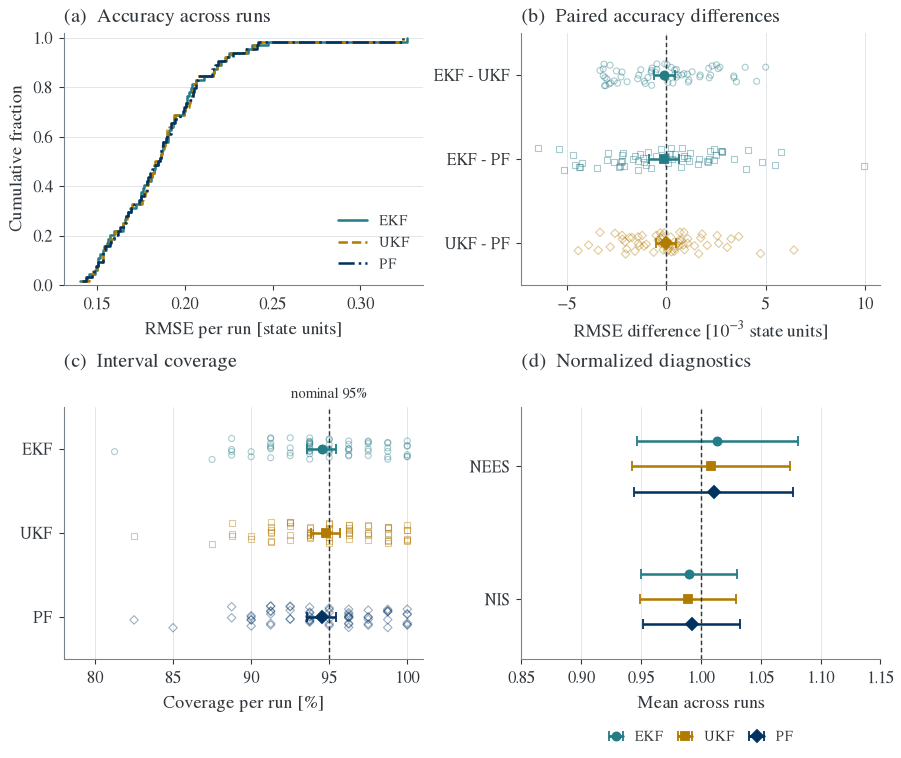

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(6.9, 5.8), layout='constrained')

# (a) Each curve uses one RMSE value per independent run.
ax = axes[0, 0]
for j, method in enumerate(methods):
    sorted_rmse = np.sort(run_rmse[:, j])
    cumulative = np.arange(1, len(sorted_rmse) + 1)/len(sorted_rmse)
    ax.step(sorted_rmse, cumulative, where='post', color=colors[j],
            linestyle=line_styles[j], label=method)
ax.set_title('(a)  Accuracy across runs', loc='left')
ax.set(xlabel='RMSE per run [state units]', ylabel='Cumulative fraction', ylim=(0, 1.02))
ax.grid(axis='y')
ax.legend(loc='lower right', fontsize=8)

# (b) Light marks show paired runs. Solid marks and bars show mean and 95% t interval.
ax = axes[0, 1]
pairs = [(0, 1), (0, 2), (1, 2)]
jitter = np.random.default_rng(7).uniform(-.13, .13, config['runs'])
for row, (a, b) in enumerate(pairs):
    differences = 1000*(run_rmse[:, a] - run_rmse[:, b])
    center, half_width = mean_interval(differences)
    ax.scatter(differences, row + jitter, s=11, facecolors='none',
               edgecolors=colors[a], alpha=.4, linewidths=.6, marker=markers[row])
    ax.errorbar(center, row, xerr=half_width, color=colors[a], marker=markers[row],
                markersize=4.5, capsize=3, linewidth=1.4, zorder=4)
ax.axvline(0, color=ink, linewidth=.8, linestyle=(0, (3, 2)))
ax.set_title('(b)  Paired accuracy differences', loc='left')
ax.set(yticks=range(3), yticklabels=['EKF - UKF', 'EKF - PF', 'UKF - PF'],
       xlabel=r'RMSE difference [$10^{-3}$ state units]', ylim=(2.5, -.5))
ax.grid(axis='x')

# (c) Each point is a run's fraction of states inside the nominal 95% interval.
ax = axes[1, 0]
for j in range(3):
    values = 100*run_coverage[:, j]
    center, half_width = mean_interval(values)
    ax.scatter(values, j + jitter, s=11, facecolors='none', edgecolors=colors[j],
               alpha=.4, linewidths=.6, marker=markers[j])
    ax.errorbar(center, j, xerr=half_width, color=colors[j], marker=markers[j],
                markersize=4.5, capsize=3, linewidth=1.4, zorder=4)
ax.axvline(95, color=ink, linewidth=.8, linestyle=(0, (3, 2)))
ax.text(95, -.56, 'nominal 95%', ha='center', va='bottom', fontsize=8, color=ink)
ax.set_title('(c)  Interval coverage', loc='left', pad=22)
ax.set(yticks=range(3), yticklabels=methods, xlabel='Coverage per run [%]',
       xlim=(78, 101), ylim=(2.5, -.5))
ax.grid(axis='x')

# (d) Average within each run first, then summarize those independent run means.
ax = axes[1, 1]
for j, method in enumerate(methods):
    for row, statistic in enumerate((run_nees, run_nis)):
        center, half_width = mean_interval(statistic[:, j])
        ax.errorbar(center, row + (j - 1)*.19, xerr=half_width, color=colors[j],
                    marker=markers[j], markersize=4.5, capsize=3, linewidth=1.4,
                    label=method if row == 0 else None)
ax.axvline(1, color=ink, linewidth=.8, linestyle=(0, (3, 2)))
ax.set_title('(d)  Normalized diagnostics', loc='left', pad=22)
ax.set(yticks=[0, 1], yticklabels=['NEES', 'NIS'], xlabel='Mean across runs',
       ylim=(1.45, -.45), xlim=(.85, 1.15))
ax.grid(axis='x')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.23), ncol=3, fontsize=8,
          handlelength=1., columnspacing=1.)

fig.savefig(figures / 'comparison-diagnostics.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(figures / 'comparison-diagnostics.png')
plt.show()

The three RMSE distributions nearly coincide. Their paired mean differences are small and the uncertainty bars include zero. Coverage is close to the nominal 95%, and both normalized diagnostics are close to one. This benchmark therefore supports comparable performance in this particular mildly nonlinear scenario. It does not establish that the algorithms are interchangeable under strong nonlinearity, ambiguous observations, incorrect noise models, or a tighter computational budget.

The particle count is fixed, and execution times are not compared. A runtime comparison would require controlled hardware, repeated timing and an accuracy-versus-cost study. Increasing the nonlinearity is a different experiment; it should be identified as such rather than used to make these plots appear more dramatic.

**Figure exports**

- `../figures/comparison-trajectory.pdf` and `.png`: run 1 with method-specific central intervals.
- `../figures/comparison-diagnostics.pdf` and `.png`: accuracy distributions, paired differences, coverage and normalized diagnostics.